# Equity Analysis 

## check for any tickers on the SEC website: 

https://www.sec.gov/files/company_tickers.json

C:\Users\alexa\jlab314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Please choose the ticker of a firm you would like to analyse which is listed by the
Securities and Exchange Comission (SEC). E.g: Apple (AAPL), IBM (IBM) or Costco (COST) AAPL



You have choosen: Apple Inc.

 Apple Inc. falls under the industry catergory of Electronic Computers 
 according to recent SEC data.

################################################
############# SCORE CARD (Millions) ############
################################################

 Apple Inc. ... Electronic Computers


SCORE CARD
Net Income: 112010.0 

Revenue: 416161.0 

###############  OPERATING DATA: ################

Operating Income: 133050.0 

Operating Expenses: 283111.0 

Operating Margin (decimal): 0.3197 

################################################


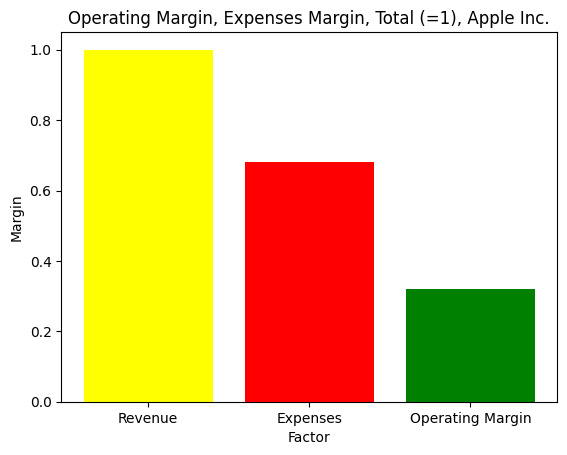

Electronic Computers


Do you wish to download Apple Inc. Income Statement Scorecard data (csv) - Y/N? N


No download


In [1]:
from edgar import set_identity
from edgar import Company

import pandas as pd
import math
import matplotlib.pyplot as plt 

set_identity("Alex alexandrosap1@outlook.com")

######## Firm selector ############

# select indivdual firm:

def individual_analysis():
    
    firm = str(input("Please choose the ticker of a firm you would like to analyse which is listed by the\nSecurities and Exchange Comission (SEC). E.g: Apple (AAPL), IBM (IBM) or Costco (COST)"))

    try:
        
        FOI = Company(firm) # FOI = Firm of interest

        FOI_fin = FOI.get_financials()
        
        FOI_rev = FOI_fin.get_revenue() /1e6
        FOI_net_income = FOI_fin.get_net_income() / 1e6
        FOI_op_income = FOI_fin.get_operating_income() / 1e6
        
        FOI_op_EXP = FOI_rev - FOI_op_income
        
        FOI_op_Marg = FOI_op_income / FOI_rev

        FOI_op_Marg_decimal = round(FOI_op_Marg, 4)
        
        print("\nYou have choosen:", FOI.name)
        print("\n", FOI.name, "falls under the industry catergory of", FOI.industry, "\n according to recent SEC data.")
        print("\n################################################")
        print("############# SCORE CARD (Millions) ############")
        print("################################################")
        print("\n", FOI.name, "...", FOI.industry)
        print("\n")
        print("SCORE CARD")
        print("Net Income:", FOI_net_income, "\n")
        print("Revenue:", FOI_rev, "\n")
        
        print("###############  OPERATING DATA: ################\n")

        print("Operating Income:", FOI_op_income, "\n")
        print("Operating Expenses:", FOI_op_EXP, "\n")
        print("Operating Margin (decimal):", FOI_op_Marg_decimal, "\n")
        
        print("################################################")

        
        
        categories = ["Revenue", "Expenses", "Operating Margin"]
        values = [1, 1- FOI_op_Marg_decimal, FOI_op_Marg_decimal]
        colors = ["yellow", "red", "green"]
        plt.bar(categories, values, color = colors)
        plt.title(f'Operating Margin, Expenses Margin, Total (=1), {FOI.name}')
        plt.xlabel('Factor')
        plt.ylabel('Margin')
        plt.show()
        print(FOI.industry)
        
        def FOI_download():
            ScoreCard_FOI = pd.DataFrame({
                "Company" : [FOI.name],
                "Sector" : [FOI.industry],
                "Revenue" : [FOI_rev],
                "Net Income" : [FOI_net_income],
                "Operating Income": [FOI_op_income],
                "Operating Expenses" : [FOI_op_EXP],
                "Operating Margin %" : [100*FOI_op_Marg_decimal]
            })

            choice_data_FOI = str(input(f"Do you wish to download {FOI.name} Income Statement Scorecard data (csv) - Y/N?"))
            if choice_data_FOI == "Y":
                
                ScoreCard_FOI.to_csv(f"{FOI.name}_Income_Statement_Scorecard.csv", 
                      index = False)
            else:
                print("No download")
                
        FOI_download()
            
    except Exception as e:
        
        print(f"Invalid ticker: {e}")
        
individual_analysis() 